**Step 2: Characterize hubs and network structure**

This notebook provides the descriptive foundation for the revised research questions.

**RQ1 (structural determinants of resilience):** To what extent do airline networks' structural properties influence their resilience to random and targeted airport disruptions beyond what is expected from their degree sequences?

**RQ2 (identifying critical airports):** Which network measures best predict the loss of connectivity caused by a single airport removal, and do community-bridging measures add information beyond degree?

The measures below describe hubs, concentration, connectivity and clustering. They do not test H1, H2 or H3. Comparisons between American, Delta and Southwest are exploratory and descriptive.

1. Part 1 — Load the three networks

In [4]:

from google.colab import drive
drive.mount("/content/drive")

import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

from pathlib import Path

# Your actual Google Drive directory
BASE = Path("/content/drive/MyDrive/Network Analysis /Data")
RAW = BASE / "raw"
PROCESSED = BASE / "Processed"

# Store figures and tables outside the Data folder
PROJECT_ROOT = BASE.parent
RESULTS = PROJECT_ROOT / "Results"
FIGURES = RESULTS / "Figures"
TABLES = RESULTS / "Tables"

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

AIRLINES = {
    "AA": "American Airlines",
    "DL": "Delta Air Lines",
    "WN": "Southwest Airlines"
}

print("Project directory:", PROJECT_ROOT)
print("Processed directory exists:", PROCESSED.exists())
print("Available processed files:")

for file in sorted(PROCESSED.glob("*.csv")):
    print(" -", file.name)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/Network Analysis 
Processed directory exists: True
Available processed files:
 - AA_edges.csv
 - AA_nodes.csv
 - DL_edges.csv
 - DL_nodes.csv
 - WN_edges.csv
 - WN_nodes.csv
 - network_summary.csv


2. Reconstruct the graphs

In [5]:

graphs = {}

for airline in AIRLINES:
    nodes_path = PROCESSED / f"{airline}_nodes.csv"
    edges_path = PROCESSED / f"{airline}_edges.csv"

    assert nodes_path.exists(), f"Missing: {nodes_path}"
    assert edges_path.exists(), f"Missing: {edges_path}"

    nodes = pd.read_csv(nodes_path)
    edges = pd.read_csv(edges_path)

    G = nx.DiGraph(airline=airline)

    for row in nodes.itertuples(index=False):
        G.add_node(
            int(row.airport_id),
            code=row.code,
            city=row.city,
            state=row.state
        )

    for row in edges.itertuples(index=False):
        G.add_edge(
            int(row.source),
            int(row.target),
            frequency=float(row.frequency)
        )

    graphs[airline] = G

    assert G.number_of_nodes() == len(nodes)
    assert G.number_of_edges() == len(edges)

    print(
        f"{airline}: "
        f"{G.number_of_nodes()} airports, "
        f"{G.number_of_edges()} directed routes"
    )

print("\nAll three networks loaded successfully!")


AA: 230 airports, 1808 directed routes
DL: 212 airports, 1506 directed routes
WN: 104 airports, 1792 directed routes

All three networks loaded successfully!


Part 2 — Basic network properties


Calculate basic statistics

In [6]:

network_stats = []

for airline, G in graphs.items():

    n = G.number_of_nodes()
    m = G.number_of_edges()

    sccs = list(nx.strongly_connected_components(G))
    largest_scc = max(map(len, sccs))

    network_stats.append({
        "Airline": airline,
        "Airports": n,
        "Directed routes": m,
        "Density": nx.density(G),
        "Avg in-degree": m / n,
        "Avg out-degree": m / n,
        "Reciprocity": nx.reciprocity(G),
        "Largest SCC (%)": 100 * largest_scc / n,
        "Number of SCCs": len(sccs)
    })

stats_df = pd.DataFrame(network_stats)

display(stats_df.round(4))

stats_df.to_csv(
    TABLES / "02_network_statistics.csv",
    index=False
)


,Airline,Airports,Directed routes,Density,Avg in-degree,Avg out-degree,Reciprocity,Largest SCC (%),Number of SCCs
0,AA,230,1808,0.0343,7.8609,7.8609,1.0,100.0,1
1,DL,212,1506,0.0337,7.1038,7.1038,1.0,100.0,1
2,WN,104,1792,0.1673,17.2308,17.2308,1.0,100.0,1


Part 3 — Degree and strength centrality

Compute airport-level degree and strength

In [7]:

airport_rows = []

for airline, G in graphs.items():

    for airport in G.nodes():

        airport_rows.append({
            "Airline": airline,
            "AirportID": airport,
            "Code": G.nodes[airport]["code"],

            "In-degree": G.in_degree(airport),
            "Out-degree": G.out_degree(airport),

            "In-strength": G.in_degree(
                airport, weight="frequency"
            ),

            "Out-strength": G.out_degree(
                airport, weight="frequency"
            )
        })

airports_df = pd.DataFrame(airport_rows)

airports_df["Total degree"] = (
    airports_df["In-degree"]
    + airports_df["Out-degree"]
)

airports_df["Total strength"] = (
    airports_df["In-strength"]
    + airports_df["Out-strength"]
)

display(airports_df.head())

airports_df.to_csv(
    TABLES / "02_airport_degree_strength.csv",
    index=False
)


,Airline,AirportID,Code,In-degree,Out-degree,In-strength,Out-strength,Total degree,Total strength
0,AA,10135,ABE,1,1,182.0,182.0,2,364.0
1,AA,10136,ABI,1,1,439.0,439.0,2,878.0
2,AA,10140,ABQ,4,4,1450.0,1449.0,8,2899.0
3,AA,10154,ACK,5,5,60.0,60.0,10,120.0
4,AA,10155,ACT,1,1,273.0,273.0,2,546.0


Display the top ten hub

In [8]:

for airline, name in AIRLINES.items():

    print(f"\n{name} — Top 10 airports by out-degree")

    top = (
        airports_df[airports_df["Airline"] == airline]
        .sort_values("Out-degree", ascending=False)
        .head(10)
    )

    display(
        top[
            [
                "Code",
                "In-degree",
                "Out-degree",
                "In-strength",
                "Out-strength"
            ]
        ]
    )



American Airlines — Top 10 airports by out-degree


,Code,In-degree,Out-degree,In-strength,Out-strength
59,DFW,182,182,70954.0,70954.0
46,CLT,136,136,56030.0,56036.0
161,ORD,136,136,37153.0,37138.0
169,PHX,92,92,23236.0,23237.0
168,PHL,88,88,24581.0,24587.0
57,DCA,86,86,23124.0,23128.0
141,MIA,75,75,19498.0,19500.0
125,LGA,58,58,12142.0,12145.0
120,LAX,45,45,10700.0,10698.0
115,JFK,24,24,5878.0,5887.0



Delta Air Lines — Top 10 airports by out-degree


,Code,In-degree,Out-degree,In-strength,Out-strength
241,ATL,154,154,72429.0,72417.0
372,MSP,118,118,26907.0,26914.0
290,DTW,100,100,27169.0,27178.0
420,SLC,89,89,21271.0,21299.0
347,LGA,75,75,20992.0,21019.0
339,JFK,57,57,14803.0,14807.0
256,BOS,54,54,12806.0,12807.0
413,SEA,47,47,12868.0,12868.0
344,LAX,44,44,12587.0,12587.0
243,AUS,23,23,4771.0,4769.0



Southwest Airlines — Top 10 airports by out-degree


,Code,In-degree,Out-degree,In-strength,Out-strength
465,DEN,86,86,23588.0,23586.0
463,DAL,75,75,17959.0,17957.0
498,MDW,75,75,17732.0,17735.0
449,BNA,73,73,14864.0,14862.0
488,LAS,71,71,22657.0,22660.0
454,BWI,67,67,18659.0,18653.0
478,HOU,61,61,13229.0,13228.0
541,STL,57,57,10742.0,10740.0
517,PHX,56,56,17767.0,17768.0
497,MCO,51,51,11901.0,11902.0


Part 4 — Degree distributions

Plot out-degree distributions

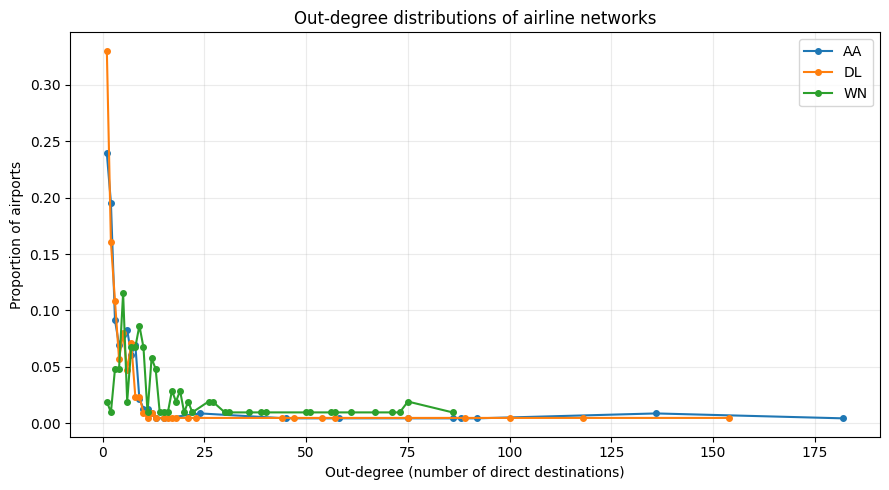

In [9]:

fig, ax = plt.subplots(figsize=(9, 5))

for airline in AIRLINES:

    G = graphs[airline]

    degrees = np.array([
        G.out_degree(node)
        for node in G.nodes()
    ])

    values, counts = np.unique(
        degrees,
        return_counts=True
    )

    probabilities = counts / counts.sum()

    ax.plot(
        values,
        probabilities,
        marker="o",
        markersize=4,
        linewidth=1.5,
        label=airline
    )

ax.set_xlabel("Out-degree (number of direct destinations)")
ax.set_ylabel("Proportion of airports")
ax.set_title("Out-degree distributions of airline networks")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    FIGURES / "02_outdegree_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


**Interpretation**

A network where a small number of airports have very high degree and most have low degree is structurally heterogeneous.
Such a distribution is consistent with hub concentration.
But a heavy-tailed degree distribution is not sufficient evidence of a scale-free network.

Compare busiest hubs by flight frequency

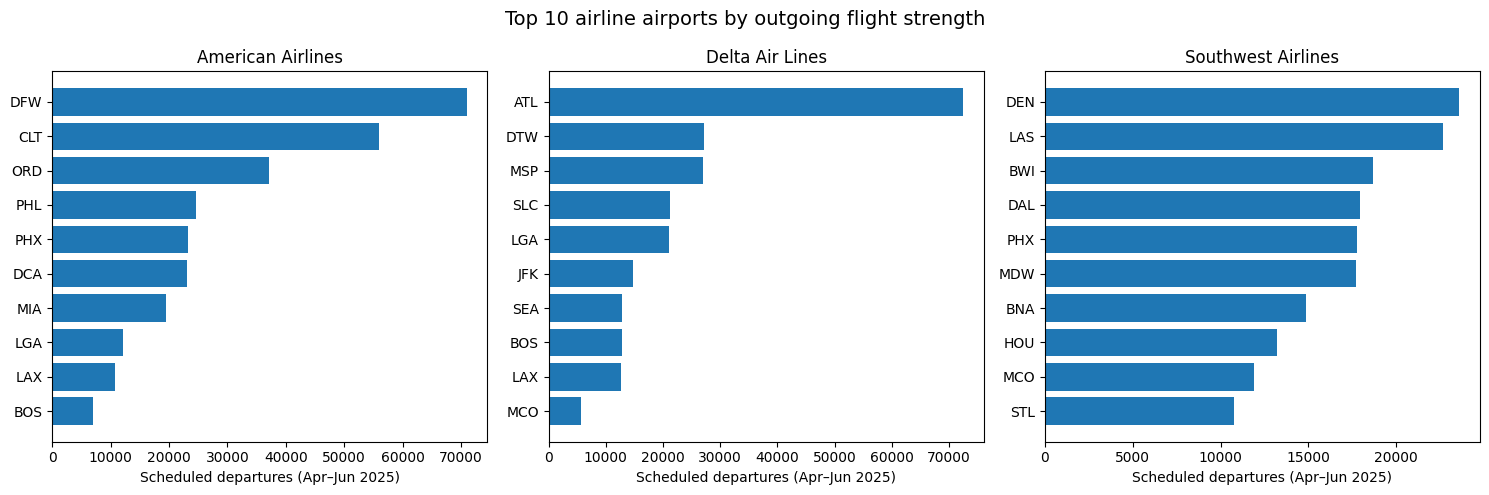

In [10]:

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (airline, name) in zip(
    axes, AIRLINES.items()
):

    top = (
        airports_df[
            airports_df["Airline"] == airline
        ]
        .nlargest(10, "Out-strength")
        .sort_values("Out-strength")
    )

    ax.barh(
        top["Code"],
        top["Out-strength"]
    )

    ax.set_title(name)
    ax.set_xlabel("Scheduled departures (Apr–Jun 2025)")

fig.suptitle(
    "Top 10 airline airports by outgoing flight strength",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURES / "02_top_airports_strength.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


This comparison illustrates operational concentration.

Part 5 — Hub dependence and network centralization

Compute hub concentration

In [11]:

def gini(values):
    x = np.asarray(values, dtype=float)

    if len(x) == 0 or np.sum(x) == 0:
        return np.nan

    x = np.sort(x)
    n = len(x)

    return (
        2 * np.sum(np.arange(1, n + 1) * x)
        / (n * np.sum(x))
        - (n + 1) / n
    )


def degree_centralization(G):
    # Convert to a simple undirected graph
    U = nx.Graph(G)

    n = U.number_of_nodes()

    if n < 3:
        return np.nan

    degrees = np.array(
        [d for _, d in U.degree()],
        dtype=float
    )

    return (
        np.sum(degrees.max() - degrees)
        / ((n - 1) * (n - 2))
    )


concentration = []

for airline, G in graphs.items():

    out_strengths = [
        G.out_degree(v, weight="frequency")
        for v in G.nodes()
    ]

    concentration.append({
        "Airline": airline,
        "Degree centralization": degree_centralization(G),
        "Out-strength Gini": gini(out_strengths)
    })

concentration_df = pd.DataFrame(concentration)

display(concentration_df.round(4))

concentration_df.to_csv(
    TABLES / "02_hub_concentration.csv",
    index=False
)


,Airline,Degree centralization,Out-strength Gini
0,AA,0.7671,0.7324
1,DL,0.7028,0.7379
2,WN,0.6808,0.6166


Important: Higher centralization might imply vulnerability, but we cannot establish that from these measurements alone. Our disruption experiments will test whether centralization corresponds to greater accessibility loss.

Part 6 — Betweenness centrality

Compute betweenness centrality

In [12]:

betweenness_rows = []

for airline, G in graphs.items():

    bc = nx.betweenness_centrality(
        G,
        normalized=True,
        weight=None
    )

    for airport, score in bc.items():

        betweenness_rows.append({
            "Airline": airline,
            "AirportID": airport,
            "Betweenness": score
        })

betweenness_df = pd.DataFrame(betweenness_rows)

airports_df = airports_df.merge(
    betweenness_df,
    on=["Airline", "AirportID"],
    how="left",
    validate="one_to_one"
)

for airline in AIRLINES:

    print(f"\n{airline} — Top airports by betweenness")

    display(
        airports_df[
            airports_df["Airline"] == airline
        ]
        .nlargest(10, "Betweenness")
        [
            [
                "Code",
                "Out-degree",
                "Out-strength",
                "Betweenness"
            ]
        ]
    )



AA — Top airports by betweenness


,Code,Out-degree,Out-strength,Betweenness
59,DFW,182,70954.0,0.463147
46,CLT,136,56036.0,0.213599
161,ORD,136,37138.0,0.184926
169,PHX,92,23237.0,0.102219
168,PHL,88,24587.0,0.051415
57,DCA,86,23128.0,0.041851
141,MIA,75,19500.0,0.022032
125,LGA,58,12145.0,0.016951
120,LAX,45,10698.0,0.015560
115,JFK,24,5887.0,0.009585



DL — Top airports by betweenness


,Code,Out-degree,Out-strength,Betweenness
241,ATL,154,72417.0,0.453007
372,MSP,118,26914.0,0.234271
420,SLC,89,21299.0,0.185204
290,DTW,100,27178.0,0.140851
347,LGA,75,21019.0,0.066698
413,SEA,47,12868.0,0.040870
339,JFK,57,14807.0,0.033611
243,AUS,23,4769.0,0.022827
344,LAX,44,12587.0,0.017243
256,BOS,54,12807.0,0.012335



WN — Top airports by betweenness


,Code,Out-degree,Out-strength,Betweenness
465,DEN,86,23586.0,0.148103
488,LAS,71,22660.0,0.109876
463,DAL,75,17957.0,0.091847
498,MDW,75,17735.0,0.082946
449,BNA,73,14862.0,0.078345
454,BWI,67,18653.0,0.072023
478,HOU,61,13228.0,0.067169
517,PHX,56,17768.0,0.043941
541,STL,57,10740.0,0.039987
497,MCO,51,11902.0,0.031877


What makes this particularly interesting?
We can compare airports ranked by:
- Degree — direct connectivity.
- Strength — scheduled flight volume.
- Betweenness — importance for indirect shortest paths.
If the highest-degree airports are not the highest-betweenness airports, this may indicate that different forms of structural importance do not coincide.
Later, Student 4 will test which of these measures best predicts the damage caused by simulated airport closures.

Part 7 — Clustering, assortativity, and shortest paths

Compute structural measures

In [13]:

structural_rows = []

for airline, G in graphs.items():

    # Undirected binary projection
    U = nx.Graph(G)

    clustering = nx.average_clustering(U)

    assortativity = nx.degree_assortativity_coefficient(U)

    # Directed shortest paths (unweighted flight legs)
    reachable_distances = []

    for source, lengths in nx.all_pairs_shortest_path_length(G):

        reachable_distances.extend(
            distance
            for target, distance in lengths.items()
            if target != source
        )

    mean_path = (
        np.mean(reachable_distances)
        if reachable_distances
        else np.nan
    )

    possible_pairs = (
        G.number_of_nodes()
        * (G.number_of_nodes() - 1)
    )

    reachability = (
        len(reachable_distances) / possible_pairs
        if possible_pairs > 0
        else np.nan
    )

    structural_rows.append({
        "Airline": airline,
        "Avg clustering": clustering,
        "Degree assortativity": assortativity,
        "Mean reachable path length": mean_path,
        "Reachability fraction": reachability
    })

structural_df = pd.DataFrame(structural_rows)

display(structural_df.round(4))

structural_df.to_csv(
    TABLES / "02_additional_structure.csv",
    index=False
)


,Airline,Avg clustering,Degree assortativity,Mean reachable path length,Reachability fraction
0,AA,0.7142,-0.7025,2.1142,1.0
1,DL,0.6011,-0.6671,2.2000,1.0
2,WN,0.7842,-0.5417,1.9042,1.0


Part 8 — Final comparison and exports

In [14]:

final_summary = (
    stats_df
    .merge(
        concentration_df,
        on="Airline",
        validate="one_to_one"
    )
    .merge(
        structural_df,
        on="Airline",
        validate="one_to_one"
    )
)

print("Final network comparison:")
display(final_summary.round(4))

final_summary.to_csv(
    TABLES / "02_final_network_comparison.csv",
    index=False
)

airports_df.to_csv(
    TABLES / "02_airport_centralities.csv",
    index=False
)

print("\nExport completed.")
print("Tables saved to:", TABLES)


Final network comparison:


,Airline,Airports,Directed routes,Density,Avg in-degree,Avg out-degree,Reciprocity,Largest SCC (%),Number of SCCs,Degree centralization,Out-strength Gini,Avg clustering,Degree assortativity,Mean reachable path length,Reachability fraction
0,AA,230,1808,0.0343,7.8609,7.8609,1.0,100.0,1,0.7671,0.7324,0.7142,-0.7025,2.1142,1.0
1,DL,212,1506,0.0337,7.1038,7.1038,1.0,100.0,1,0.7028,0.7379,0.6011,-0.6671,2.2000,1.0
2,WN,104,1792,0.1673,17.2308,17.2308,1.0,100.0,1,0.6808,0.6166,0.7842,-0.5417,1.9042,1.0



Export completed.
Tables saved to: /content/drive/MyDrive/Network Analysis /Results/Tables


Validate the results

In [15]:

for airline, G in graphs.items():

    row = final_summary[
        final_summary["Airline"] == airline
    ].iloc[0]

    assert 0 <= row["Density"] <= 1
    assert 0 <= row["Largest SCC (%)"] <= 100
    assert 0 <= row["Degree centralization"] <= 1
    assert 0 <= row["Out-strength Gini"] <= 1
    assert 0 <= row["Avg clustering"] <= 1
    assert 0 <= row["Reachability fraction"] <= 1

    # Inbound and outbound frequency sums should match
    inbound = sum(
        degree
        for _, degree in G.in_degree(weight="frequency")
    )

    outbound = sum(
        degree
        for _, degree in G.out_degree(weight="frequency")
    )

    assert np.isclose(inbound, outbound)

    # No invalid edge frequencies
    assert all(
        data["frequency"] > 0
        for _, _, data in G.edges(data=True)
    )

print("PASS: All structural checks completed.")


PASS: All structural checks completed.


Part 8b: Reproducible supporting statistics and conventions

**Projections used in this notebook.** All three observed networks are perfectly reciprocal in binary terms, so every route appears in both directions.

| Measure | Representation |
|---|---|
| Degree, strength | Directed; strength sums `frequency` |
| Degree centralization | Undirected binary projection, Freeman normalization by (n-1)(n-2) |
| Out-strength Gini | Directed weighted out-strength |
| Betweenness | Directed binary hops (`weight=None`) |
| Average clustering, transitivity, assortativity | Undirected binary projection |
| Reachability, mean path length, SCCs | Directed binary |

Flight frequency is not used as a distance or as a clustering weight anywhere in this notebook.

In [ ]:
# Statistics quoted in the interpretation below, now computed and exported here.
supporting_rows = []

for airline in AIRLINES:
    airline_airports = airports_df[airports_df["Airline"] == airline]

    spearman = airline_airports["Out-degree"].corr(
        airline_airports["Betweenness"],
        method="spearman"
    )

    top_five = airline_airports.nlargest(5, "Out-strength")
    top_five_share = 100 * top_five["Out-strength"].sum() / airline_airports["Out-strength"].sum()

    supporting_rows.append({
        "Airline": airline,
        "Spearman out-degree vs betweenness": spearman,
        "Top-5 airport share of departures (%)": top_five_share,
        "Top-5 airports by out-strength": ", ".join(top_five["Code"])
    })

supporting_df = pd.DataFrame(supporting_rows)
display(supporting_df.round(3))

supporting_df.to_csv(
    TABLES / "02_spearman_top5_shares.csv",
    index=False
)

,Airline,Spearman out-degree vs betweenness,Top-5 airport share of departures (%),Top-5 airports by out-strength
0,AA,0.645,41.219,"DFW, CLT, ORD, PHL, PHX"
1,DL,0.684,40.313,"ATL, DTW, MSP, SLC, LGA"
2,WN,0.885,27.968,"DEN, LAS, BWI, DAL, PHX"


**Average local clustering versus transitivity**

Both measures are computed on the undirected binary projection, but they answer different questions.

- **Average local clustering** gives each airport its own neighbour-connectivity score and then averages the scores with equal weight per airport. A small airport connected to two hubs that are linked to each other scores 1.0, so hub-and-spoke networks with many such airports can have high values.
- **Transitivity** is the share of all connected triples, across the whole network, that close into triangles. High-degree hubs contribute most triples, and a hub's many spokes are mostly not connected to one another, so hub-and-spoke networks have low values.

Neither is the "correct" one. They should be reported together, and a statement about which airline is "more clustered" should name the measure.

In [ ]:
clustering_rows = []

for airline, G in graphs.items():
    # Undirected binary projection, without edge attributes
    U = nx.Graph()
    U.add_nodes_from(G.nodes())
    U.add_edges_from(G.edges())

    clustering_rows.append({
        "Airline": airline,
        "Average local clustering": nx.average_clustering(U),
        "Transitivity": nx.transitivity(U)
    })

clustering_df = pd.DataFrame(clustering_rows)
display(clustering_df.round(4))

clustering_df.to_csv(
    TABLES / "02_clustering_vs_transitivity.csv",
    index=False
)

,Airline,Average local clustering,Transitivity
0,AA,0.7142,0.1194
1,DL,0.6011,0.1406
2,WN,0.7842,0.3708


Part 9 — Interpret the findings for the report

## Step 2: Descriptive Results and Interpretation (exploratory airline comparison)

### Analysis A — Hub Concentration

American Airlines (AA) and Delta Air Lines (DL) exhibit stronger hub concentration than Southwest Airlines (WN). AA has the highest degree centralization on the undirected binary projection (0.767), followed by DL (0.703) and WN (0.681). Flight-frequency inequality follows a similar pattern: DL (Gini = 0.738) and AA (0.732) exceed WN (0.617).

The five busiest airports account for approximately 41.2% of AA's and 40.3% of DL's scheduled departures, compared with 28.0% for WN. This suggests that Southwest distributes its operations more evenly across airports, while American and Delta depend more heavily on dominant hubs.

### Analysis B — Network Organization

Southwest has substantially higher network density (0.167) than American (0.034) and Delta (0.034), despite serving fewer airports. WN has the highest average local clustering (0.784), followed by AA (0.714) and DL (0.601). WN also has the highest transitivity (0.371), but the AA and DL order reverses under that measure (DL 0.141, AA 0.119), so the AA-versus-DL ordering depends on the measure used (see Part 8b).

All three networks exhibit negative degree assortativity (AA: −0.703, DL: −0.667, WN: −0.542), consistent with hub-and-spoke connectivity. However, this pattern is less pronounced for Southwest.

All networks are fully strongly connected, with 100% pairwise reachability. Southwest also has the shortest mean reachable path length (1.904 flight legs), compared with AA (2.114) and DL (2.200).

### Analysis C — Hub Importance vs. Betweenness

The airports with the greatest outgoing flight volumes generally also have high betweenness centrality. DFW leads American (0.463), ATL leads Delta (0.453), and DEN leads Southwest (0.148).

However, degree, flight strength, and betweenness are not interchangeable. Spearman correlations between out-degree and betweenness are 0.645 for AA, 0.684 for DL, and 0.885 for WN. This indicates that direct connectivity is more closely associated with shortest-path importance in Southwest's network.

Overall, American and Delta show greater hub dependence, whereas Southwest exhibits a denser, more interconnected, and more evenly distributed route structure. **These findings suggest different potential vulnerabilities but do not establish which network is most resilient.** That question will be investigated through airport-removal simulations.

**One particularly interesting descriptive finding (exploratory)**

Southwest's density is approximately five times higher than American's or Delta's, despite its smaller airport network. At the same time, Southwest has lower hub concentration and shorter paths. Its clustering is also highest under both clustering measures reported above.

This raises an exploratory question for the disruption experiments: does Southwest's denser and less concentrated network retain a greater share of its connectivity under targeted removals than American's and Delta's? Any comparison must use normalized losses at equal fractions of airports removed, because the networks differ in size and geographic coverage. With three airlines this is a case-study comparison, not a hypothesis test.

The formal hypothesis is different. **H2 (beyond-degree structure):** resilience in an observed airline network differs systematically from that of its own directed degree-preserving randomized counterparts under matched removal experiments. H2 compares each airline with its own null ensemble, not with the other airlines.

Degree-based hub concentration is preserved by the degree-sequence null model, so it cannot be claimed as an additional beyond-degree effect. A real-versus-null difference would show that the preserved in-degrees and out-degrees do not fully account for the result; it would not by itself prove that communities or cores caused it.